# ST1519 CA1 Group 1 

## How to run this notebook

Use a Jupyter Python kernel with pandas and Matplotlib installed. The data-preparation checks were verified with pandas 3.0.1.

1. Put `customers_base.csv`, `orders_base.csv`, and `labels_base.csv` in the same folder.
2. In **2.1 Load the historical CSVs**, set `DATA_DIR` to that folder. Keep `Path(".")` if the Jupyter kernel is running from the data folder. Use `Path(r"C:\path\to\data")` to point to a different folder on Windows.
3. Run all cells from top to bottom. The final cell writes one prepared dataset, `base_processed.csv`, to the kernel's working directory.

Each modelling notebook loads that file, creates its train, validation and test sets, and fits any learned preprocessing on its training rows.

## 1️⃣Objective and Setup

### Prediction target and timing
We want to predict whether an order is fraudulent so the Trust & Safety team can review suspicious orders before shipment. Each prediction is for one order. The target is `is_fraud` from `labels_base.csv`, where `1` means fraud and `0` means non-fraud.

### Source files and composite keys
`customers_base.csv` contains customer information, `orders_base.csv` contains order details, and `labels_base.csv` links orders to customers and records the fraud outcome. We link labels to orders using `(country_code, order_id)` and to customers using `(country_code, customer_id)`.

## 2️⃣Exploratory Data Analysis (EDA) 
### 2.1 Load the historical CSVs 
Set `DATA_DIR` to the folder containing all three CSVs. Use `Path(".")` when Jupyter runs from that folder.

`load_batch` accepts local paths or public CSV URLs. The base filenames belong to this notebook run. The later ETL supplies the three sources for each batch.

In [57]:
from pathlib import Path

import pandas as pd

# Load each CSV into its own DataFrame, keeping identifiers as text.
def load_batch(customers_csv_source, orders_csv_source, labels_csv_source):
    """Read customer, order, and label CSVs from local paths or public URLs."""
    return {
        "Customers": pd.read_csv(
            customers_csv_source,
            dtype={"country_code": "string", "customer_id": "string", "mobile_verified": "string"},
        ),
        "Orders": pd.read_csv(
            orders_csv_source,
            dtype={"country_code": "string", "order_id": "string"},
        ),
        "Labels": pd.read_csv(
            labels_csv_source,
            dtype={"country_code": "string", "order_id": "string", "customer_id": "string"},
        ),
    }

# Resolve the CSV filenames relative to the notebook kernel's working directory.
DATA_DIR = Path(r"C:\Users\Shaun Tan\OneDrive - Singapore Polytechnic (Micole)\OneDrive - Singapore Polytechnic\Y2S2\Agile MLoPs\CA1\datasets"
)
datasets = load_batch(
    DATA_DIR / "customers_base.csv",
    DATA_DIR / "orders_base.csv",
    DATA_DIR / "labels_base.csv",
)
customers_base = datasets["Customers"]
orders_base = datasets["Orders"]
labels_base = datasets["Labels"]

for name, dataset in datasets.items():
    rows, columns = dataset.shape
    print(f"{name}: {rows:,} rows, {columns} columns")

Customers: 901,312 rows, 9 columns
Orders: 949,889 rows, 8 columns
Labels: 950,318 rows, 4 columns


### 2.2 Dataset structure

#### Dataset dimensions

In [58]:
# Make one summary row per dataset from its shape.
pd.DataFrame(
    [{"Dataset": name, "Rows": df.shape[0], "Columns": df.shape[1]}
     for name, df in datasets.items()]
).set_index("Dataset")

,Rows,Columns
Dataset,,
Customers,901312,9
Orders,949889,8
Labels,950318,4


**Conclusion.** The labels file has 429 more rows than the orders file. The row counts alone leave the number of matching orders unknown. During preprocessing, we will join by country code and order ID and report unmatched records.

#### Column names and data types

In [59]:
# Combine the per-column data types and missing-value counts into one table.
column_profile = pd.concat(
    {
        name: pd.DataFrame({
            "Data type": df.dtypes.astype(str),
            "Missing rows": df.isna().sum(),
            "Missing (%)": df.isna().mean().mul(100).round(6),
        })
        for name, df in datasets.items()
    },
    names=["Dataset", "Column"],
)
column_profile

Data type  Missing rows  \
Dataset   Column                                                     
Customers country_code                        string             0   
          customer_id                         string             0   
          mobile_verified                     string             0   
          num_orders_last_50days               int64             0   
          num_cancelled_orders_last_50days     int64             0   
          num_refund_orders_last_50days        int64             0   
          total_payment_last_50days          float64             0   
          num_associated_customers             int64             0   
          first_order_datetime                object           712   
Orders    country_code                        string             0   
          order_id                            string             0   
          collect_type                        object             0   
          payment_method                      object         21501   
          order_value                        float64             0   
          num_items_ordered                  float64             1   
          refund_value                       float64             0   
          order_date                          object             0   
Labels    country_code                        string             0   
          order_id                            string             0   
          customer_id                         string             0   
          is_fraud                             int64             0   

                                            Missing (%)  
Dataset   Column                                         
Customers country_code                         0.000000  
          customer_id                          0.000000  
          mobile_verified                      0.000000  
          num_orders_last_50days               0.000000  
          num_cancelled_orders_last_50days     0.000000  
          num_refund_orders_last_50days        0.000000  
          total_payment_last_50days            0.000000  
          num_associated_customers             0.000000  
          first_order_datetime                 0.078996  
Orders    country_code                         0.000000  
          order_id                             0.000000  
          collect_type                         0.000000  
          payment_method                       2.263528  
          order_value                          0.000000  
          num_items_ordered                    0.000105  
          refund_value                         0.000000  
          order_date                           0.000000  
Labels    country_code                         0.000000  
          order_id                             0.000000  
          customer_id                          0.000000  
          is_fraud                             0.000000

**Conclusion.** Country codes and IDs are text because they identify records for joins. Both date columns load as text, so they need to be parsed before comparing dates and calculating date-based features. `num_items_ordered` loads as a float because one value is missing, even though it represents a whole-number count. `is_fraud` is stored as an integer and has no missing values. It is the classification target, with `0` for non-fraud and `1` for fraud. During preprocessing, we will preserve identifiers as text, parse the dates, and store item counts as nullable integers.

### 2.3 Data quality

In [60]:
# Define the columns that identify one record in each table.
key_columns_by_dataset = {
    "Customers": ["country_code", "customer_id"],
    "Orders": ["country_code", "order_id"],
    "Labels": ["country_code", "order_id"],
}

def normalise_country_codes(country_codes):
    return country_codes.str.strip().str.upper()


# Check duplicates and blank keys on a copy with normalised country codes.
def summarise_key_quality(df, key_columns):
    normalized_keys = df[key_columns].copy()
    normalized_keys["country_code"] = normalise_country_codes(normalized_keys["country_code"])
    return {
        "Exact duplicate rows": df.duplicated().sum(),
        "Duplicate normalized keys": normalized_keys.duplicated().sum(),
        "Rows with missing or blank keys": (
            normalized_keys.isna() | normalized_keys.apply(lambda column: column.str.strip().eq(""))
        ).any(axis=1).sum(),
    }

pd.DataFrame({name: summarise_key_quality(df, key_columns_by_dataset[name]) for name, df in datasets.items()}).T

,Exact duplicate rows,Duplicate normalized keys,Rows with missing or blank keys
Customers,0,0,0
Orders,0,0,0
Labels,0,0,0


**Conclusion.** All three files have zero exact duplicates, duplicate keys after country-code normalisation, and missing or blank keys. We will repeat these checks after normalising country codes in each incoming batch.

#### Country codes, mobile verification, and date formats

In [61]:
# Align the counts by country code and fill absent codes with zero.
country_code_counts = pd.concat(
    {name: df["country_code"].value_counts() for name, df in datasets.items()},
    axis=1,
).fillna(0).astype(int)
country_code_counts

,Customers,Orders,Labels
country_code,,,
MY,339134,360569,360586
PH,289358,281211,281239
PK,151877,184822,184840
TH,72509,63727,63788
BD,48044,59560,59564
pk,225,0,0
my,165,0,121
ph,0,0,180


**Conclusion.** Customers contains `pk` and `my` alongside uppercase codes, while labels contains `my` and `ph` alongside uppercase codes. Orders uses uppercase throughout. During preprocessing, we will trim and uppercase country codes across all three tables so matching keys use the same format.

In [62]:
# Count each raw verification value, including missing values.
customers_base["mobile_verified"].value_counts(dropna=False).rename("Rows").to_frame()

,Rows
mobile_verified,
True,900681
False,466
yes,165


**Conclusion.** `mobile_verified` contains 165 `yes` values. During preprocessing, we will convert `yes` and `True` to boolean `True` because both indicate a verified phone number. We will convert `False` to boolean `False` and flag unexpected values.

In [63]:
# Count dates that match YYYY-MM-DD and other non-missing date strings.
order_date_format_counts = pd.Series({
    "ISO date (YYYY-MM-DD)": orders_base["order_date"].str.fullmatch(
        r"\d{4}-\d{2}-\d{2}", na=False
    ).sum(),
    "Other non-missing date text": (
        orders_base["order_date"].notna()
        & ~orders_base["order_date"].str.fullmatch(r"\d{4}-\d{2}-\d{2}", na=False)
    ).sum(),
}, name="Rows")
order_date_format_counts.to_frame()

,Rows
ISO date (YYYY-MM-DD),200
Other non-missing date text,949689


**Conclusion.** Only 200 of the 949,889 order dates use the `YYYY-MM-DD` format. During preprocessing, we will parse the mixed formats into dates so date-based features can be calculated.

In [64]:
def parse_batch_dates(date_values):
    """Parse the source date formats and leave invalid dates missing."""
    return pd.to_datetime(date_values, format="mixed", errors="coerce")


# Count non-missing inputs that became missing during date parsing.
def count_unparseable_dates(date_values):
    return (date_values.notna() & parse_batch_dates(date_values).isna()).sum()


def summarise_invalid_values(customers, orders, labels):
    # Convert item counts to numbers so invalid text and fractional counts can be flagged.
    item_counts = pd.to_numeric(orders["num_items_ordered"], errors="coerce")
    invalid_item_counts = orders["num_items_ordered"].notna() & (
        item_counts.isna() | item_counts.le(0) | item_counts.mod(1).ne(0)
    )

    def count_invalid_amounts(raw_amounts):
        amounts = pd.to_numeric(raw_amounts, errors="coerce")
        return (raw_amounts.notna() & (
            amounts.isna() | amounts.lt(0) | amounts.eq(float("inf"))
        )).sum()

    return pd.Series({
        "Unparseable order dates": count_unparseable_dates(orders["order_date"]),
        "Unparseable first-order dates": count_unparseable_dates(customers["first_order_datetime"]),
        "Invalid or missing fraud labels": (
            ~pd.to_numeric(labels["is_fraud"], errors="coerce").isin([0, 1])
        ).sum(),
        "Invalid item counts": invalid_item_counts.sum(),
        "Invalid order values": count_invalid_amounts(orders["order_value"]),
        "Invalid refund values": count_invalid_amounts(orders["refund_value"]),
    }, name="Rows").to_frame()


summarise_invalid_values(customers_base, orders_base, labels_base)

,Rows
Unparseable order dates,0
Unparseable first-order dates,0
Invalid or missing fraud labels,0
Invalid item counts,0
Invalid order values,0
Invalid refund values,0


**Conclusion.** All non-missing dates parsed successfully, all fraud labels were 0 or 1, and the numeric checks found zero invalid values. We will rerun these checks on incoming batches and flag values that fail.

#### Missing values by column

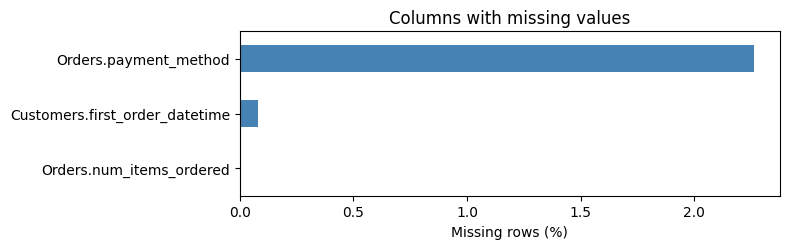

In [65]:
import matplotlib.pyplot as plt

# Select only columns with missing values for the chart.
missing_percentages = column_profile.loc[column_profile["Missing rows"].gt(0), "Missing (%)"]
missing_percentages.index = [f"{dataset}.{column}" for dataset, column in missing_percentages.index]
ax = missing_percentages.sort_values().plot.barh(figsize=(8, 2.6), color="steelblue")
ax.set(xlabel="Missing rows (%)", title="Columns with missing values")
plt.tight_layout()
plt.show()

In [66]:
# Print the exact counts and percentages for the bars above.
missing_value_summary = column_profile.loc[
    column_profile["Missing rows"].gt(0), ["Missing rows", "Missing (%)"]
].sort_values("Missing rows", ascending=False)

print(missing_value_summary.to_string(float_format=lambda value: f"{value:.6f}"))

                                Missing rows  Missing (%)
Dataset   Column                                         
Orders    payment_method               21501     2.263528
Customers first_order_datetime           712     0.078996
Orders    num_items_ordered                1     0.000105


**Observation.** Payment method has the longest bar at 2.26%, followed by first-order date at 0.079%. The item-count bar is barely visible because only one row is missing.

**Conclusion.** Missingness is concentrated in payment method. We will use `Unknown` for missing payment methods in the model data and keep unknown dates and item counts missing in the cleaned tables.

### 2.4 Numerical distributions and outliers

In [67]:
# Summarise numeric features with percentiles to show how far the upper tail extends.
numeric_distribution_summary = pd.concat(
    {
        name: df.select_dtypes(include="number").describe(percentiles=[0.5, 0.95, 0.99]).T
        for name, df in datasets.items()
        if name != "Labels"
    },
    names=["Dataset", "Column"],
)
numeric_distribution_summary.round(2)

count    mean     std  min  \
Dataset   Column                                                            
Customers num_orders_last_50days            901312.0   21.71   26.28  0.0   
          num_cancelled_orders_last_50days  901312.0    0.26    1.01  0.0   
          num_refund_orders_last_50days     901312.0    0.23    0.86  0.0   
          total_payment_last_50days         901312.0  302.18  425.80  0.0   
          num_associated_customers          901312.0    2.69    6.37  1.0   
Orders    order_value                       949889.0    6.94    6.46  0.0   
          num_items_ordered                 949888.0    3.67    5.01  1.0   
          refund_value                      949889.0    2.24    3.92  0.0   

                                               50%      95%      99%       max  
Dataset   Column                                                                
Customers num_orders_last_50days             14.00    70.00   117.00   2162.00  
          num_cancelled_orders_last_50days    0.00     1.00     3.00    259.00  
          num_refund_orders_last_50days       0.00     1.00     3.00    107.00  
          total_payment_last_50days         164.58  1057.94  1876.68  42569.35  
          num_associated_customers            2.00     6.00    17.00    101.00  
Orders    order_value                         5.51    17.64    30.98    662.88  
          num_items_ordered                   2.00    10.00    22.00   1600.00  
          refund_value                        0.93     8.82    16.86    518.00

**Conclusion.** The highest order value is SGD 662.88, compared with SGD 30.98 at the 99th percentile. During preprocessing, we will review unusually large order values and retain valid orders.

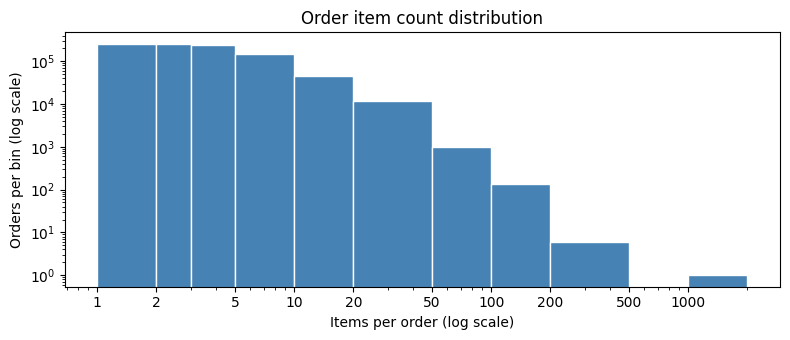

In [68]:
# Use wider bins in the tail to include large orders without hiding small ones.
items_per_order = orders_base["num_items_ordered"].dropna()
item_count_bins = [1, 2, 3, 5, 10, 20, 50, 100, 200, 500, 1000]
while item_count_bins[-1] <= items_per_order.max():
    item_count_bins.append(item_count_bins[-1] * 2)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(items_per_order, bins=item_count_bins, color="steelblue", edgecolor="white")
ax.set(
    xscale="log", yscale="log",
    xlabel="Items per order (log scale)", ylabel="Orders per bin (log scale)",
    title="Order item count distribution",
)
ticks = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
ax.set_xticks(ticks, labels=[str(value) for value in ticks])
fig.tight_layout()
plt.show()

**Why log scales?** On the x-axis, the log scale keeps small baskets readable while fitting item counts up to 1,600. On the y-axis, each major step is a tenfold increase in orders, so bins with only a few orders are visible alongside bins with hundreds of thousands. The histogram shows counts per bin. The exact statistics below come from the original item counts.

In [69]:
# Summarise the item counts behind the histogram.
item_count_summary = items_per_order.describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
item_count_summary = item_count_summary.rename(index={
    "25%": "25th percentile",
    "50%": "50th percentile (median)",
    "75%": "75th percentile",
    "95%": "95th percentile",
    "99%": "99th percentile",
})
print(f"Orders with a recorded item count: {items_per_order.count():,}")
print()
print(item_count_summary.drop("count").rename(index={
    "mean": "Mean (average)",
    "std": "Standard deviation",
    "min": "Minimum",
    "max": "Maximum",
}).rename_axis("Statistic").to_frame("Items per order").to_string(
    float_format=lambda value: f"{value:,.2f}"
))

Orders with a recorded item count: 949,888

                          Items per order
Statistic                                
Mean (average)                       3.67
Standard deviation                   5.01
Minimum                              1.00
25th percentile                      1.00
50th percentile (median)             2.00
75th percentile                      4.00
95th percentile                     10.00
99th percentile                     22.00
Maximum                          1,600.00


**Observation.** The histogram is concentrated at small item counts. The table shows a median of 2 items and a 99th percentile of 22, while the maximum reaches 1,600 items.

**Conclusion.** Order sizes are right-skewed. We will keep valid large orders and calculate value per item only for valid, positive counts.

### 2.5 Fraud label distribution

In [70]:
# Count each target class and divide by the total to get its percentage.
fraud_label_counts = labels_base["is_fraud"].value_counts(dropna=False).sort_index()
pd.DataFrame({
    "Orders": fraud_label_counts,
    "Share (%)": fraud_label_counts.div(fraud_label_counts.sum()).mul(100).round(2),
})

,Orders,Share (%)
is_fraud,,
0,845814,89.0
1,104504,11.0


**Conclusion.** Fraud accounts for 104,504 of 950,318 labels (11.0%), so non-fraud labels outnumber fraud labels by about 8 to 1. Modelling will use metrics such as precision and recall to assess fraud detection.

### 2.6 EDA findings and preprocessing decisions

| Finding | Follow-up |
|---|---|
| Mixed-case country codes | Trim and uppercase before checking keys and joining. |
| Mixed order-date formats and 712 missing first-order dates | Parse the date formats, report failures, and leave unknown dates missing. |
| 165 `yes` values in `mobile_verified` | Map `yes` and `True` to boolean `True`, map `False` to boolean `False`, and flag unexpected values. |
| 21,501 missing payment methods and one missing item count | Use an `Unknown` payment category for modelling and keep the missing item count null in cleaned data. |
| Labels has 429 more rows than orders | Check which keys match after country-code normalization and report unmatched records. |
| Extreme numeric values | Review the largest records and retain valid extremes. |
| 11.0% fraud labels | Use precision and recall to assess the minority class during model evaluation. |

## 3️⃣Preprocessing and Feature Engineering

### 3.1 Clean the source tables 

`clean_batch` applies the same rules to any batch. It returns three cleaned tables and an audit. Optional missing values stay missing. Rows with unusable keys, order dates, or labels are excluded and counted. If rows share a key and disagree, all conflicting rows are excluded.

In [71]:
def clean_table_keys(raw_table, key_columns):
    table = raw_table.copy()
    table["country_code"] = normalise_country_codes(table["country_code"].astype("string"))
    for column in key_columns:
        if column != "country_code":
            table[column] = table[column].astype("string").str.strip()
    invalid_key = ~table["country_code"].str.fullmatch(r"[A-Z]{2}", na=False)
    invalid_key |= table[key_columns].fillna("").eq("").any(axis=1)
    return table.loc[~invalid_key].copy(), {
        "Input rows": len(raw_table),
        "Invalid key rows": int(invalid_key.sum()),
    }


def resolve_duplicate_keys(table, key_columns, audit):
    # Compare standardised values before deciding whether records disagree.
    distinct_rows = table.drop_duplicates()
    conflicting_keys = distinct_rows.duplicated(key_columns, keep=False)
    audit["Repeated rows removed"] = len(table) - len(distinct_rows)
    audit["Conflicting key rows"] = int(conflicting_keys.sum())
    return distinct_rows.loc[~conflicting_keys].copy(), audit


def clean_customer_records(raw_customers):
    customers, audit = clean_table_keys(raw_customers, ["country_code", "customer_id"])
    # Convert the supported verification strings to nullable booleans.
    verification = customers["mobile_verified"].astype("string").str.strip().str.lower()
    mapped = verification.map({"true": True, "yes": True, "false": False})
    audit["Unexpected verification values"] = int((verification.notna() & mapped.isna()).sum())
    customers["mobile_verified"] = mapped.astype("boolean")
    # Parse first-order dates and count non-missing values that failed to parse.
    first_order = parse_batch_dates(customers["first_order_datetime"])
    audit["Unparseable first-order dates"] = int(
        (customers["first_order_datetime"].notna() & first_order.isna()).sum()
    )
    customers["first_order_datetime"] = first_order
    return resolve_duplicate_keys(customers, ["country_code", "customer_id"], audit)


def clean_order_records(raw_orders):
    orders, audit = clean_table_keys(raw_orders, ["country_code", "order_id"])
    # Parse order dates, keep the calendar day, and filter rows without a usable date.
    orders["order_date"] = parse_batch_dates(orders["order_date"]).dt.normalize()
    invalid_date = orders["order_date"].isna()
    audit["Missing or invalid order dates"] = int(invalid_date.sum())
    orders = orders.loc[~invalid_date].copy()

    # Convert item counts to numbers so invalid text and fractional counts can be flagged.
    item_counts = pd.to_numeric(orders["num_items_ordered"], errors="coerce")
    valid_counts = item_counts.gt(0) & item_counts.mod(1).eq(0) & item_counts.lt(2**63)
    audit["Invalid item counts set to missing"] = int(
        (orders["num_items_ordered"].notna() & ~valid_counts).sum()
    )
    orders["num_items_ordered"] = item_counts.where(valid_counts).astype("Int64")
    # Keep finite, non-negative amounts and set invalid amounts to missing.
    for column in ("order_value", "refund_value"):
        amounts = pd.to_numeric(orders[column], errors="coerce")
        valid_amount = amounts.ge(0) & amounts.lt(float("inf"))
        audit[f"Invalid {column} set to missing"] = int(
            (orders[column].notna() & ~valid_amount).sum()
        )
        orders[column] = amounts.where(valid_amount)
    # Standardise category casing and whitespace, then treat blanks as missing.
    for column in ("payment_method", "collect_type"):
        orders[column] = orders[column].astype("string").str.strip().str.lower().replace("", pd.NA)
    return resolve_duplicate_keys(orders, ["country_code", "order_id"], audit)


def clean_label_records(raw_labels):
    labels, audit = clean_table_keys(raw_labels, ["country_code", "order_id"])
    labels["customer_id"] = labels["customer_id"].astype("string").str.strip()
    missing_customer = labels["customer_id"].fillna("").eq("")
    # Convert the target to a number and keep only 0 or 1.
    fraud_values = pd.to_numeric(labels["is_fraud"], errors="coerce")
    invalid_label = ~fraud_values.isin([0, 1])
    audit["Missing customer IDs"] = int(missing_customer.sum())
    audit["Invalid or missing fraud labels"] = int(invalid_label.sum())
    valid_rows = ~(missing_customer | invalid_label)
    labels = labels.loc[valid_rows].copy()
    labels["is_fraud"] = fraud_values.loc[valid_rows].astype("int8")
    return resolve_duplicate_keys(labels, ["country_code", "order_id"], audit)


def clean_batch(raw_customers, raw_orders, raw_labels):
    """Apply the same cleaning rules to any batch loaded from CSV."""
    # Run the three cleaners and collect their row counts in one audit table.
    results = {
        "Customers": clean_customer_records(raw_customers),
        "Orders": clean_order_records(raw_orders),
        "Labels": clean_label_records(raw_labels),
    }
    cleaned = {name: table for name, (table, _) in results.items()}
    audit = pd.DataFrame.from_dict({
        name: {**counts, "Cleaned rows": len(table)}
        for name, (table, counts) in results.items()
    }, orient="index").astype("Int64")
    return cleaned, audit

#### Verify cleaning results

In [72]:
cleaned_tables, cleaning_audit = clean_batch(customers_base, orders_base, labels_base)
cleaning_audit.T

,Customers,Orders,Labels
Input rows,901312,949889,950318
Invalid key rows,0,0,0
Unexpected verification values,0,<NA>,<NA>
Unparseable first-order dates,0,<NA>,<NA>
Repeated rows removed,0,0,0
Conflicting key rows,0,0,0
Cleaned rows,901312,949889,950318
Missing or invalid order dates,<NA>,0,<NA>
Invalid item counts set to missing,<NA>,0,<NA>
Invalid order_value set to missing,<NA>,0,<NA>


**Conclusion.** All base rows passed the required-field checks. The 165 `yes` values now count as verified, and the missing first-order dates, payment methods, and item count remain missing in the cleaned tables.

### 3.2 Join labels to orders and customers 

First, join labels to orders on `(country_code, order_id)`. Then join to customers on `(country_code, customer_id)`. Each label can match one order, and several labels can match the same customer. Left joins keep every label visible in the audit.

In [73]:
def join_labelled_orders(labels, orders, customers):
    # Keep every label and record whether each of its two joins found a match.
    joined = labels.merge(
        orders, on=["country_code", "order_id"], how="left",
        validate="one_to_one", indicator="order_match",
    ).merge(
        customers, on=["country_code", "customer_id"], how="left",
        validate="many_to_one", indicator="customer_match",
    )
    # Keep fully matched records for features and return the remaining label keys for review.
    has_order = joined["order_match"].eq("both")
    has_customer = joined["customer_match"].eq("both")
    matched = joined.loc[has_order & has_customer].drop(
        columns=["order_match", "customer_match"]
    )
    unmatched = joined.loc[~(has_order & has_customer), [
        "country_code", "order_id", "customer_id", "order_match", "customer_match"
    ]].copy()
    return matched, unmatched


matched_orders, unmatched_labels = join_labelled_orders(
    cleaned_tables["Labels"], cleaned_tables["Orders"], cleaned_tables["Customers"]
)
assert len(matched_orders) + len(unmatched_labels) == len(cleaned_tables["Labels"])
pd.Series({
    "Fully matched": len(matched_orders),
    "Missing order only": (
        unmatched_labels["order_match"].eq("left_only")
        & unmatched_labels["customer_match"].eq("both")
    ).sum(),
    "Missing customer only": (
        unmatched_labels["customer_match"].eq("left_only")
        & unmatched_labels["order_match"].eq("both")
    ).sum(),
    "Missing both": (
        unmatched_labels["order_match"].eq("left_only")
        & unmatched_labels["customer_match"].eq("left_only")
    ).sum(),
}, name="Label rows").to_frame()

,Label rows
Fully matched,949872
Missing order only,432
Missing customer only,2
Missing both,12


**Conclusion.** 949,872 labels matched both tables. The other 446 remain in the join audit and are excluded from the model dataset.

### 3.3 Build features for order review 

| Feature | Why it may help |
|---|---|
| Days since first order | Measures how recently the customer started ordering. |
| Value per item | Measures how expensive the order is relative to its size. |
| Order weekday | Captures possible differences in ordering patterns across the week. |

Use order details available before shipment. Refunds and the customer snapshot fields stay out of the model inputs because they may include information from after the order. The customer ID and order ID are retained for tracing.

In [74]:
# List the columns intended as model inputs, excluding IDs and the target.
MODEL_FEATURE_COLUMNS = [
    "country_code", "collect_type", "payment_method", "order_value",
    "num_items_ordered", "days_since_first_order", "value_per_item", "order_weekday",
]


def build_order_features(labelled_orders):
    model_data = labelled_orders[[
        "country_code", "order_id", "customer_id", "order_date",
        "collect_type", "payment_method", "order_value", "num_items_ordered", "is_fraud",
    ]].copy()
    # Compare calendar days and leave negative or unknown elapsed times missing.
    first_order_day = labelled_orders["first_order_datetime"].dt.normalize()
    days_since_first_order = (model_data["order_date"] - first_order_day).dt.days
    model_data["days_since_first_order"] = days_since_first_order.where(
        days_since_first_order.ge(0)
    ).astype("Int64")
    # Use positive item counts as the denominator so missing or zero counts yield no ratio.
    positive_item_count = model_data["num_items_ordered"].where(
        model_data["num_items_ordered"].gt(0)
    )
    model_data["value_per_item"] = model_data["order_value"].div(positive_item_count)
    model_data["order_weekday"] = model_data["order_date"].dt.day_name()
    # Represent missing payment methods as a category in the model dataset.
    model_data["payment_method"] = model_data["payment_method"].fillna("Unknown")
    return model_data


model_data = build_order_features(matched_orders)
assert len(model_data) == len(matched_orders)
assert model_data["days_since_first_order"].dropna().ge(0).all()
assert model_data["value_per_item"].dropna().ge(0).all()
model_data[MODEL_FEATURE_COLUMNS].isna().sum().rename("Missing rows").to_frame()

,Missing rows
country_code,0
collect_type,0
payment_method,0
order_value,0
num_items_ordered,1
days_since_first_order,876
value_per_item,1
order_weekday,0


**Conclusion.** Feature creation keeps one row per matched order. Days since first order stays missing when the first-order date is unknown or later than the labelled order, and value per item stays missing without a valid denominator.

### 3.4 Reuse in automated ETL

1. Call `load_batch` with the three local paths or public CSV URLs.
2. Pass the returned tables to `clean_batch`. Save the audit and write the cleaned tables to RDS.
3. Read the combined historical and incoming tables from RDS, then call `join_labelled_orders`. A new label can refer to an order or customer already in the database.
4. Pass the matched rows to `build_order_features`. Pass the resulting order-level dataset to the model training workflow.

The functions take their data as arguments and return tables or audits. When the automated script is built, move the function definitions and their shared helpers into one Python module that both the script and notebook can import.

## 4 Export the Prepared Dataset

`base_processed.csv` contains one row per matched order, with engineered features, the fraud label, and the original order date and identifiers. The export preserves the row order of the prepared data. Each modelling notebook creates its own split and fits imputation, encoding, or scaling on its training set.

In [75]:
output_path = Path("base_processed.csv")
model_data.to_csv(output_path, index=False)
print(f"Exported {len(model_data):,} prepared orders to {output_path}.")

Exported 949,872 prepared orders to base_processed.csv.
